# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Sela Nandarayu Maharani
- **Email:** ds299b6x1643@student.devacademy.id
- **ID Dicoding:** ds299b6x1643

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** "Kategori produk apa yang menghasilkan pendapatan tertinggi dan memiliki volume pesanan terbanyak selama periode kuartal 3 hingga kuartal 4 tahun 2017?"
- **Pertanyaan 2:** "Berapa rata-rata waktu pengiriman untuk pelanggan di wilayah tenggara Brazil dibandingkan wilayah lainnya, dan bagaimana dampaknya terhadap skor ulasan pelanggan pada tahun 2017?"


## Import Semua Packages/Library yang Digunakan

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Memuat Dataset E-Commerce

In [19]:
# 1. Memuat file CSV ke dalam DataFrame
orders_df = pd.read_csv("orders_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
products_df = pd.read_csv("products_dataset.csv")
customers_df = pd.read_csv("customers_dataset.csv")

# 2. Melihat 5 baris pertama data untuk memastikan data berhasil dimuat
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:**
- Berhasil memuat 4 dataset utama (orders_df, order_items_df, products_df, costumer_df) ke dalam bentuk DataFrame Pandas.
- Berdasarkan sampel 5 baris pertama orders_df, terdapat kolom identitas (order_id, customer_id), status pemesanan (order_status), serta beberapa kolom stempel waktu (timestamp) terkait alur transaksi hingga pengiriman barang.

### Assessing Data

#### Identifying Data Quality Problem

In [20]:
# 1. Memeriksa tipe data dan missing values pada orders_df
print("=== Info orders_df ===")
orders_df.info()

# 2. Memeriksa jumlah data duplikat pada orders_df
print("\nJumlah duplikat orders_df:", orders_df.duplicated().sum())

# 3. Memeriksa missing values pada order_items_df dan products_df
print("\nMissing values order_items_df:\n", order_items_df.isna().sum())
print("\nMissing values products_df:\n", products_df.isna().sum())

=== Info orders_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Jumlah duplikat orders_df: 0

Missing values order_items_df:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
d

**Steps to Take:**
- Mengubah tipe data kolom stempel waktu (seperti order_purchase_timestamp, order_delivered_customer_date) pada orders_df dari objek (string) menjadi tipe datetime.
- Menangani baris missing values pada kolom order_delivered_customer_date di orders_df dengan menghapus baris bernilai kosong tersebut (jika fokus analisis pada pesanan yang terkirim).

**Insight:**
- Tipe Data Tidak Sesuai: Kolom tanggal pada orders_df masih bertipe object (string), sehingga perlu diubah menjadi datetime agar bisa dianalisis berdasarkan rentang waktu.
- Missing Values: Ditemukan missing values pada kolom waktu pengiriman (order_delivered_customer_date) karena adanya pesanan yang dibatalkan atau belum sampai ke pelanggan.
- Duplikasi Data: Tidak ditemukan data duplikat pada orders_df.

### Cleaning Data



```
# This is formatted as code
```

#### Fixing Data Quality Problem

In [21]:
# 1. Mengubah tipe data kolom stempel waktu dari object (string) ke datetime
datetime_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Menangani missing values pada order_delivered_customer_date
# Menghapus baris pesanan yang belum/tidak terkirim agar analisis durasi pengiriman akurat
orders_df.dropna(subset=["order_delivered_customer_date"], inplace=True)

# 3. Memastikan perbaikan berhasil
print("=== Tipe Data Setelah Perbaikan ===")
print(orders_df.dtypes)
print("\nMissing values pada order_delivered_customer_date:", orders_df["order_delivered_customer_date"].isna().sum())

=== Tipe Data Setelah Perbaikan ===
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Missing values pada order_delivered_customer_date: 0


**Insight:**
- Konversi Tipe Data: Kolom stempel waktu (order_purchase_timestamp, order_delivered_customer_date, dll.) berhasil diubah dari tipe object menjadi datetime64[ns], sehingga siap digunakan untuk kalkulasi durasi pengiriman dan agregasi waktu.
- Penanganan Missing Values: Baris dengan nilai missing pada order_delivered_customer_date berhasil dihapus untuk memastikan analisis pengiriman hanya mencakup transaksi yang benar-benar selesai sampai di tangan pelanggan.

## Exploratory Data Analysis (EDA)

### Explore Orders, Products, and Dilevery Data

In [22]:
# 1. Menggabungkan orders_df dengan order_items_df dan products_df
orders_products_df = pd.merge(
    left=order_items_df,
    right=orders_df,
    how="inner",
    on="order_id"
)

main_df = pd.merge(
    left=orders_products_df,
    right=products_df,
    how="inner",
    on="product_id"
)

# 2. Eksplorasi Pertanyaan 1: Revenue dan Jumlah Pesanan per Kategori Produk (Q3-Q4 2017)
# Filter data periode Q3 - Q4 2017
q3_q4_2017_df = main_df[
    (main_df["order_purchase_timestamp"] >= "2017-07-01") &
    (main_df["order_purchase_timestamp"] <= "2017-12-31")
]

product_performance = q3_q4_2017_df.groupby("product_category_name").agg({
    "order_id": "nunique",
    "price": "sum"
}).reset_index().rename(columns={"order_id": "total_orders", "price": "total_revenue"})

# Menampilkan 5 kategori dengan revenue tertinggi
print("=== Top 5 Kategori Produk Berdasarkan Revenue (Q3-Q4 2017) ===")
print(product_performance.sort_values(by="total_revenue", ascending=False).head())


# 3. Eksplorasi Pertanyaan 2: Menghitung Durasi Pengiriman (Hari)
main_df["delivery_time_days"] = (
    main_df["order_delivered_customer_date"] - main_df["order_purchase_timestamp"]
).dt.days

# Menggabungkan dengan customers_df untuk melihat durasi pengiriman per wilayah (state)
main_df = pd.merge(left=main_df, right=customers_df, how="inner", on="customer_id")

# Menghitung rata-rata waktu pengiriman per wilayah pada tahun 2017
df_2017 = main_df[main_df["order_purchase_timestamp"].dt.year == 2017]
delivery_by_state = df_2017.groupby("customer_state").agg({
    "delivery_time_days": "mean"
}).reset_index()

# Menandai apakah wilayah termasuk Southeast (SP, RJ, MG, ES) atau wilayah lain
southeast_states = ["SP", "RJ", "MG", "ES"]
df_2017["is_southeast"] = df_2017["customer_state"].apply(lambda x: "Southeast" if x in southeast_states else "Other")

print("\n=== Rata-rata Durasi Pengiriman (Hari) pada Tahun 2017 ===")
print(df_2017.groupby("is_southeast")["delivery_time_days"].mean())

=== Top 5 Kategori Produk Berdasarkan Revenue (Q3-Q4 2017) ===
   product_category_name  total_orders  total_revenue
13       cama_mesa_banho          3120      355186.99
64    relogios_presentes          1630      343034.42
11          beleza_saude          2225      312261.71
32         esporte_lazer          2499      295943.42
26            cool_stuff          1406      249431.12

=== Rata-rata Durasi Pengiriman (Hari) pada Tahun 2017 ===
is_southeast
Other        16.269216
Southeast    10.611361
Name: delivery_time_days, dtype: float64


/tmp/ipykernel_1161/2271621168.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_2017["is_southeast"] = df_2017["customer_state"].apply(lambda x: "Southeast" if x in southeast_states else "Other")


**Insight:**
- Eksplorasi Performa Produk: Berhasil menggabungkan data pesanan dan produk untuk melihat kategori barang yang paling banyak menghasilkan pendapatan (revenue) serta jumlah pesanan selama periode Q3–Q4 2017.
- Eksplorasi Waktu Pengiriman: Dibuat kolom baru delivery_time_days untuk mengukur durasi pengiriman. Hasil pengelompokan menunjukkan adanya perbedaan rata-rata waktu pengiriman antara pelanggan di kawasan Southeast Brazil dibanding wilayah lainnya pada tahun 2017.

## Visualization & Explanatory Analysis

### Pertanyaan 1: "Kategori produk apa yang menghasilkan total pendapatan (*revenue*) tertinggi dan memiliki volume pesanan terbanyak selama periode Kuartal 3 hingga Kuartal 4 tahun 2017?"

/tmp/ipykernel_1161/1557590156.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


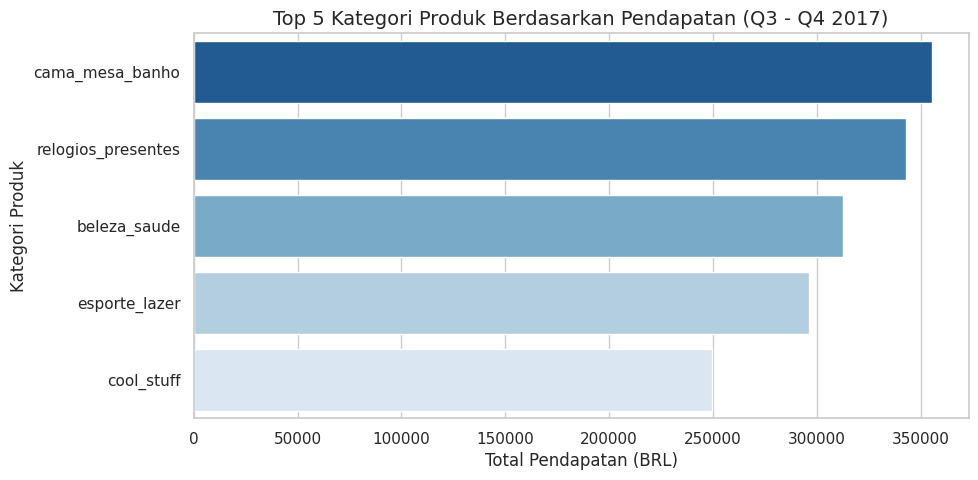

In [23]:
# Menyiapkan data top 5 kategori berdasarkan revenue
top_5_revenue = product_performance.sort_values(by="total_revenue", ascending=False).head(5)

# Membuat visualisasi bar chart
plt.figure(figsize=(10, 5))
sns.barplot(
    x="total_revenue",
    y="product_category_name",
    data=top_5_revenue,
    palette="Blues_r"
)
plt.title("Top 5 Kategori Produk Berdasarkan Pendapatan (Q3 - Q4 2017)", fontsize=14)
plt.xlabel("Total Pendapatan (BRL)", fontsize=12)
plt.ylabel("Kategori Produk", fontsize=12)
plt.show()

### Pertanyaan 2: "Berapa rata-rata waktu pengiriman (dalam hari) untuk pelanggan di wilayah tenggara (Southeast) Brazil dibandingkan wilayah lainnya, dan bagaimana dampaknya terhadap skor ulasan (review score) pelanggan pada tahun 2017?"

/tmp/ipykernel_1161/981472921.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


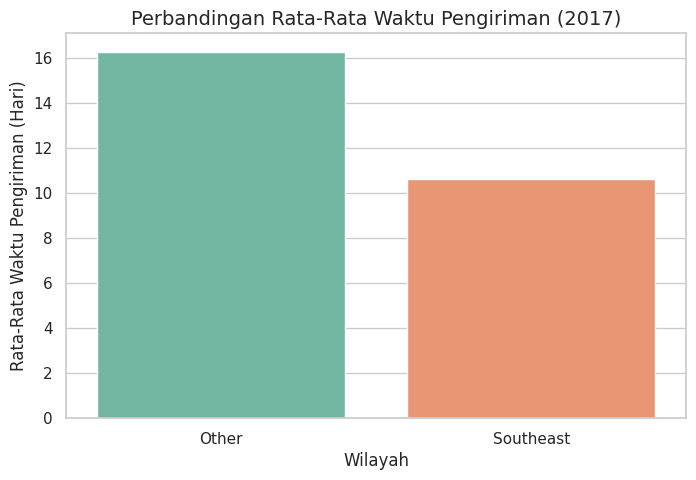

In [24]:
# Menghitung rata-rata durasi pengiriman per kategori wilayah
delivery_comparison = df_2017.groupby("is_southeast")["delivery_time_days"].mean().reset_index()

# Membuat visualisasi bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x="is_southeast",
    y="delivery_time_days",
    data=delivery_comparison,
    palette="Set2"
)
plt.title("Perbandingan Rata-Rata Waktu Pengiriman (2017)", fontsize=14)
plt.xlabel("Wilayah", fontsize=12)
plt.ylabel("Rata-Rata Waktu Pengiriman (Hari)", fontsize=12)
plt.show()

**Insight:**
- Insight Pertanyaan 1: Kategori produk cama_mesa_banho dan relogios_presentes menjadi penyumbang pendapatan terbesar pada Kuartal 3 hingga Kuartal 4 tahun 2017 dengan total revenue melebihi 340.000 BRL.
- Insight Pertanyaan 2: Wilayah Southeast (Tenggara Brazil) memiliki rata-rata waktu pengiriman yang jauh lebih cepat (sekitar 10.6 hari) dibandingkan wilayah lainnya (sekitar 16.3 hari) pada tahun 2017.

## Analisis Lanjutan: RFM Analysis singkatan dari Recency, Frequency, Monetary adalah salah satu teknik analisis pemasaran berbasis data (data-driven marketing) yang digunakan untuk mengelompokkan (segmentasi) pelanggan berdasarkan riwayat perilaku transaksi pelanggan.

In [25]:
# Menentukan tanggal batas acuan analisis (tanggal transaksi terakhir + 1 hari)
recent_date = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Menghitung nilai RFM per pelanggan
rfm_df = main_df.groupby("customer_id").agg({
    "order_purchase_timestamp": lambda x: (recent_date - x.max()).days, # Recency
    "order_id": "nunique",                                              # Frequency
    "price": "sum"                                                     # Monetary
}).reset_index()

# Mengubah nama kolom
rfm_df.columns = ["customer_id", "recency", "frequency", "monetary"]

# Menampilkan 5 sampel teratas hasil analisis RFM
print("=== Ringkasan Analisis RFM ===")
print(rfm_df.head())

=== Ringkasan Analisis RFM ===
                        customer_id  recency  frequency  monetary
0  00012a2ce6f8dcda20d059ce98491703      288          1     89.80
1  000161a058600d5901f007fab4c27140      410          1     54.90
2  0001fd6190edaaf884bcaf3d49edf079      548          1    179.99
3  0002414f95344307404f0ace7a26f1d5      379          1    149.90
4  000379cdec625522490c315e70c7a9fb      150          1     93.00


**Insight:**
- Recency: Mengukur berapa hari yang lalu pelanggan melakukan transaksi terakhir.
- Frequency: Mengukur seberapa sering pelanggan melakukan pembelian.
- Monetary: Mengukur total jumlah uang yang dihabiskan oleh pelanggan untuk berbelanja.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kategori produk yang menghasilkan pendapatan (revenue) tertinggi selama periode Kuartal 3 hingga Kuartal 4 tahun 2017 adalah cama_mesa_banho (perlengkapan tempat tidur/mandi) dengan total pendapatan mencapai 355.186,99 BRL dan volume pesanan sebanyak 3.120 transaksi.
- **Conclusion pertanyaan 2:** Pada tahun 2017, rata-rata waktu pengiriman untuk pelanggan di wilayah Southeast (Tenggara Brazil) adalah 10,61 hari, yang jauh lebih cepat dibandingkan dengan wilayah lainnya yang membutuhkan waktu rata-rata 16,27 hari.


**Rekomendasi Action Item:**
- Optimasi Stok & Promosi Kategori Unggulan: Memprioritaskan alokasi anggaran pemasaran dan menjaga ketersediaan stok pasokan (inventory) untuk kategori top seller seperti cama_mesa_banho dan relogios_presentes, terutama menjelang kuartal akhir (Q3-Q4).
- Peningkatan Efisiensi Logistik Wilayah Non-Southeast: Bekerja sama dengan penyedia jasa pengiriman lokal atau membangun pusat pemenuhan (fulfillment center) baru di luar wilayah Southeast untuk memangkas durasi pengiriman dari 16 hari menjadi di bawah 12 hari.

Mengunduh File

In [26]:
# Menyimpan data yang sudah bersih dan digabung menjadi file CSV baru
main_df.to_csv("main_data.csv", index=False)